# ДЗ 1. Персональные top-10 рекомендации комиксов и графических романов (Goodreads)

Пять моделей реализованы с нуля в `models/` (NumPy / SciPy / PyTorch) и сравниваются по единому протоколу:

| # | Модель | Файл |
|---|--------|------|
| 1 | Item-based KNN (асимметричный косинус со сжатием) | `models/item_knn.py` |
| 2 | iALS (Hu et al. 2008, регуляризация Rendle et al. 2022, CG-решатель) | `models/ials.py` |
| 3 | EASE | `models/ease.py` |
| 4 | Factorization Machine с метапризнаками (sampled softmax / BPR) | `models/fm.py` |
| 5 | iALS с собственным целевым сигналом (рейтинг + давность) | `models/ials_custom.py` |

Общий код: `models/common.py` (метрики, top-K, подбор гиперпараметров), `models/data.py` (загрузка, очистка, разбиение, признаки FM).

**Как запустить.**
1. `pip install -r requirements.txt` (в Colab всё уже установлено).
2. Данные скачиваются автоматически первой ячейкой раздела 1 в `data/` (~460 МБ, публичные ссылки UCSD); вручную:
   `wget https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/byGenre/goodreads_interactions_comics_graphic.json.gz`
   и `.../goodreads_books_comics_graphic.json.gz` в папку `data/`.
3. Запустить ноутбук сверху вниз (`Run all`). На GPU (Colab T4) полный прогон занял около 50 минут (большая часть — подбор FM), на CPU — заметно дольше.
   Все случайные параметры зафиксированы в ячейке `CONFIG`.

In [ ]:
import os, sys, subprocess
REPO_URL = "https://github.com/Samuray-228/RecSys.git"
if not os.path.isdir("models"):
    repo_dir = "/content/RecSys" if os.path.isdir("/content") else os.path.abspath("RecSys")
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True)
    os.chdir(os.path.join(repo_dir, "hw1"))
try:
    import pyarrow, torch, scipy 
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("working dir:", os.getcwd())

In [ ]:
import time, json, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import matplotlib.pyplot as plt

from models.common import (set_seed, get_device, evaluate, grid_search, expand_grid, Popularity,
                           per_user_ndcg, recommend, ranking_metrics, recency_profile)
from models.data import (download, load_interactions, load_books, PrepConfig, prepare, make_split,
                         FeatureBuilder, stack_blocks, SHELF_STOP)
from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FM
from models.ials_custom import CustomTargetIALS, custom_target

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

CONFIG = {
    "seed": 42,
    "data_dir": "data",
    "window": ("2016-01-01", "2017-11-01"), 
    "min_user": 10, "min_item": 20, 
    "max_interactions": 2_000_000,
    "val_start": "2017-09-01", 
    "test_start": "2017-10-01", 
    "test_end": "2017-11-01",
    "k": 10,
    "main_metric": "NDCG@10",
}
SEED, K, METRIC = CONFIG["seed"], CONFIG["k"], CONFIG["main_metric"]
set_seed(SEED)
DEVICE = get_device()
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Данные

**Датасет:** UCSD Book Graph — Goodreads, жанровое подмножество *Comics & Graphic*
(M. Wan, J. McAuley. *Item Recommendation on Monotonic Behavior Chains*, RecSys 2018;
M. Wan et al. *Fine-Grained Spoiler Detection from Large-Scale Review Corpora*, ACL 2019).
Страница: https://mengtingwan.github.io/data/goodreads.html, файлы — `https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/byGenre/`.

* `goodreads_interactions_comics_graphic.json.gz` — записи «полок» пользователей: `user_id`, `book_id`,
  `is_read` (книга отмечена прочитанной), `rating` (0 — без оценки, 1–5 звёзд), `review_text_incomplete`
  (текст рецензии), `date_added` (когда книга добавлена на полку), `date_updated`, `read_at`, `started_at`.
* `goodreads_books_comics_graphic.json.gz` — метаданные изданий: название, авторы, серия, издатель, формат,
  язык, год, число страниц, `work_id` (произведение, объединяющее издания), «популярные полки» (пользовательские теги).

**Что рекомендуем:** произведения (works) комиксов / графических романов, которые пользователь добавит на полку в ближайший месяц.
**Взаимодействие:** добавление книги на полку (`date_added` — его момент).
**Релевантный объект на test:** произведение, которое пользователь добавил в целевой период и **не оценил на 1–2 звезды**
(добавление «хочу прочитать», прочтение без оценки и оценка 3–5 — положительные сигналы, 1–2 — явная неудача рекомендации).
Это общий критерий для всех моделей; обучающие таргеты моделей его не меняют.

In [3]:
paths = download(CONFIG["data_dir"])
t0 = time.time()
inter = load_interactions(paths["interactions"], cache=os.path.join(CONFIG["data_dir"], "interactions.parquet"))
books = load_books(paths["books"], cache=os.path.join(CONFIG["data_dir"], "books.pkl"))
print(f"loaded in {time.time() - t0:.0f}s")
print(f"interactions: {len(inter):,}  users: {inter['user_id'].nunique():,}  books: {inter['book_id'].nunique():,}")
print(f"books metadata: {len(books):,}  works: {books['work_id'].nunique():,}")
inter.head()

loaded in 3s
interactions: 7,347,630  users: 342,415  books: 89,411
books metadata: 89,411  works: 62,944


,user_id,book_id,is_read,rating,has_review,date_added
0,8842281e1d1347389f2ab93d60773d4d,836610,False,0,False,2017-08-21 19:11:00+00:00
1,8842281e1d1347389f2ab93d60773d4d,7648967,False,0,False,2017-02-24 16:59:44+00:00
2,8842281e1d1347389f2ab93d60773d4d,15704307,False,0,False,2015-05-21 04:28:56+00:00
3,8842281e1d1347389f2ab93d60773d4d,6902644,False,0,False,2014-06-02 00:25:23+00:00
4,8842281e1d1347389f2ab93d60773d4d,9844623,False,0,False,2012-09-02 15:45:08+00:00


## 2. EDA и подготовка данных
### 2.1 Пропуски, дубликаты, некорректные значения

In [4]:
eda = {
    "date_added не распарсилась": inter["date_added"].isna().mean(),
    "date_added < 2007 (до запуска Goodreads)": (inter["date_added"] < pd.Timestamp("2007-01-01", tz="UTC")).mean(),
    "полные дубликаты (user, book)": inter.duplicated(["user_id", "book_id"]).mean(),
    "book_id без метаданных": (~inter["book_id"].isin(books["book_id"])).mean(),
    "rating = 0 (нет оценки)": (inter["rating"] == 0).mean(),
    "is_read = True": inter["is_read"].mean(),
    "есть текст рецензии": inter["has_review"].mean(),
}
display(pd.Series(eda, name="доля").to_frame().style.format("{:.4f}"))
meta_missing = pd.Series({
    "publisher": (books["publisher"] == "").mean(), "format": (books["format"] == "").mean(),
    "language": (books["language"] == "").mean(), "num_pages": books["num_pages"].isna().mean(),
    "publication_year": books["year"].isna().mean(), "series (пусто)": (books["series"].str.len() == 0).mean(),
    "authors (пусто)": (books["authors"].str.len() == 0).mean(), "popular_shelves (пусто)": (books["shelves"].str.len() == 0).mean(),
}, name="доля пропусков в метаданных")
display(meta_missing.to_frame().style.format("{:.3f}"))

,доля
date_added не распарсилась,0.0000
date_added < 2007 (до запуска Goodreads),0.0000
"полные дубликаты (user, book)",0.0000
book_id без метаданных,0.0000
rating = 0 (нет оценки),0.3856
is_read = True,0.6484
есть текст рецензии,0.0741


,доля пропусков в метаданных
publisher,0.217
format,0.243
language,0.331
num_pages,0.266
publication_year,0.207
series (пусто),0.436
authors (пусто),0.000
popular_shelves (пусто),0.000


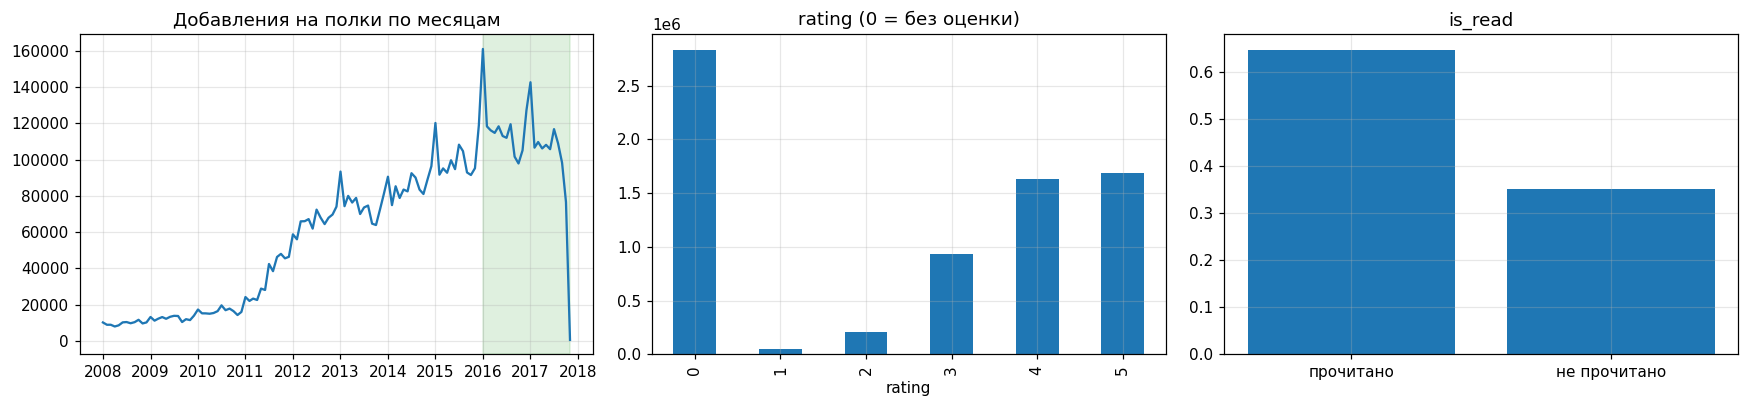

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
m = inter.set_index("date_added").resample("MS").size()
m = m[m.index >= "2008-01-01"]
ax[0].plot(m.index, m.values); ax[0].set_title("Добавления на полки по месяцам"); ax[0].axvspan(pd.Timestamp(CONFIG["window"][0]), pd.Timestamp(CONFIG["window"][1]), alpha=0.15, color="C2")
inter["rating"].value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("rating (0 = без оценки)")
r = inter[inter["rating"] > 0]
ax[2].bar(["прочитано", "не прочитано"], [inter["is_read"].mean(), 1 - inter["is_read"].mean()]); ax[2].set_title("is_read")
plt.tight_layout(); plt.show()

**Наблюдения.** Пропусков в ключевых полях почти нет; явные дубликаты (user, book) отсутствуют, но одно произведение
бывает на полке в нескольких изданиях — это скрытые дубликаты (см. ниже). Около 40% записей без оценки —
это добавления «хочу прочитать», они несут сильный неявный сигнал. Оценки смещены вверх (4–5 звёзд), 1–2 звезды
встречаются редко — это явный негатив. Активность растёт до 2015–2016 гг. и обрывается в начале ноября 2017
(момент сбора данных), поэтому последний месяц с полными данными — октябрь 2017.

### 2.2 Очистка и формирование выборки

1. Окно `date_added` ∈ [2016-01-01, 2017-11-01): актуальная часть данных, на которой поведение стационарнее
   и которая укладывается в лимит 2 млн взаимодействий без случайного прореживания пользователей.
2. Издания → произведения (`work_id`): разные издания одной книги — один объект (первое добавление,
   максимальная оценка, `is_read`/рецензия по «или»). Иначе модель «рекомендовала бы уже прочитанное» в другом издании.
3. Итеративное k-core: пользователи ≥ 10, произведения ≥ 20 взаимодействий — убирает шум и даёт
   достаточную статистику для коллаборативных моделей и размер каталога, при котором EASE (плотная матрица items×items) помещается в память.
4. Если результат > 2 млн — воспроизводимая (seed=42) подвыборка пользователей.

In [6]:
cfg = PrepConfig(start=CONFIG["window"][0], end=CONFIG["window"][1], min_user=CONFIG["min_user"],
                 min_item=CONFIG["min_item"], max_interactions=CONFIG["max_interactions"], seed=SEED)
log = []
df = prepare(inter, books, cfg, log)
log_df = pd.DataFrame(log, columns=["шаг", "взаимодействий", "пользователей", "объектов"])
display(log_df)
n_u, n_i = df["user"].nunique(), df["item"].nunique()
print(f"итог: {len(df):,} взаимодействий, {n_u:,} пользователей, {n_i:,} произведений; "
      f"плотность {len(df) / (n_u * n_i):.5f} (разреженность {1 - len(df) / (n_u * n_i):.4%})")

,шаг,взаимодействий,пользователей,объектов
0,raw,7347630,342415,89411
1,time window,2486080,178141,79715
2,"editions -> works, dedup",2480720,178141,58497
3,"k-core (user>=10, item>=20)",1855094,40907,16960


итог: 1,855,094 взаимодействий, 40,907 пользователей, 16,960 произведений; плотность 0.00267 (разреженность 99.7326%)


доля записей, где у пользователя уже есть другое издание того же произведения: 0.0033


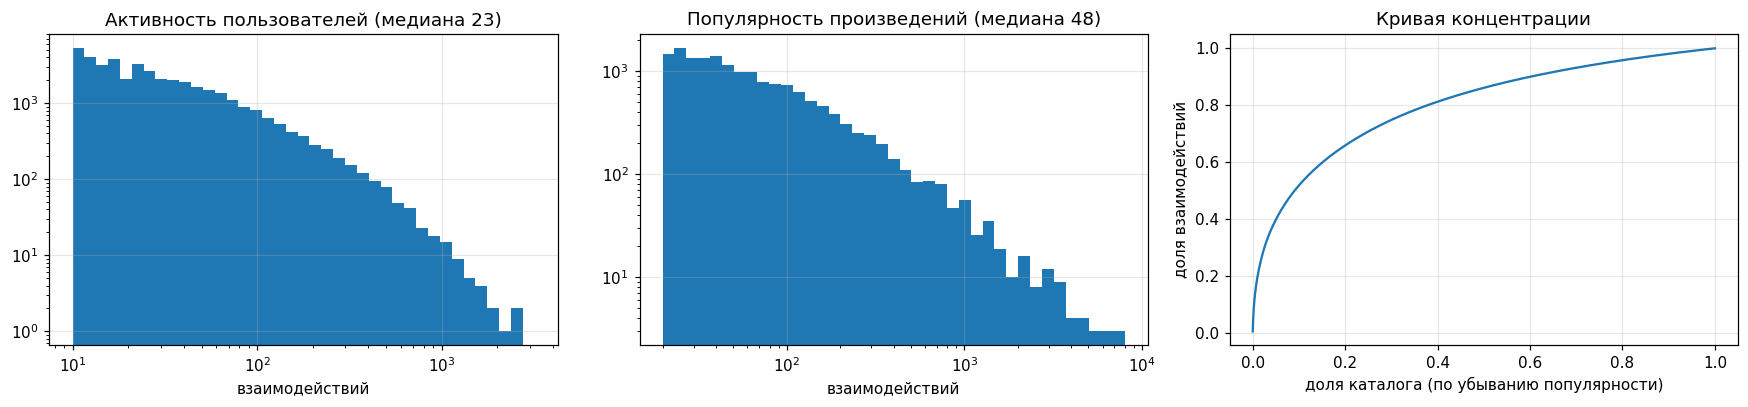

топ-1% произведений собирают 19.4% взаимодействий, топ-10% — 51.8%
        rating
mean  2.069663


In [7]:
editions = inter.merge(books[["book_id", "work_id"]], on="book_id")
dup_share = editions.duplicated(["user_id", "work_id"]).mean()
print(f"доля записей, где у пользователя уже есть другое издание того же произведения: {dup_share:.4f}")

uc = df.groupby("user").size(); ic = df.groupby("item").size()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(uc, bins=np.logspace(1, np.log10(uc.max()), 40)); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title(f"Активность пользователей (медиана {uc.median():.0f})"); ax[0].set_xlabel("взаимодействий")
ax[1].hist(ic, bins=np.logspace(np.log10(20), np.log10(ic.max()), 40)); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title(f"Популярность произведений (медиана {ic.median():.0f})"); ax[1].set_xlabel("взаимодействий")
srt = np.sort(ic.values)[::-1]
ax[2].plot(np.arange(1, len(srt) + 1) / len(srt), np.cumsum(srt) / srt.sum())
ax[2].set_title("Кривая концентрации"); ax[2].set_xlabel("доля каталога (по убыванию популярности)"); ax[2].set_ylabel("доля взаимодействий")
plt.tight_layout(); plt.show()
print(f"топ-1% произведений собирают {np.cumsum(srt)[int(len(srt) * 0.01)] / srt.sum():.1%} взаимодействий, "
      f"топ-10% — {np.cumsum(srt)[int(len(srt) * 0.1)] / srt.sum():.1%}")
print(df[["rating", "is_read", "has_review"]].describe().T[["mean"]].T)

### 2.3 Метаданные произведений

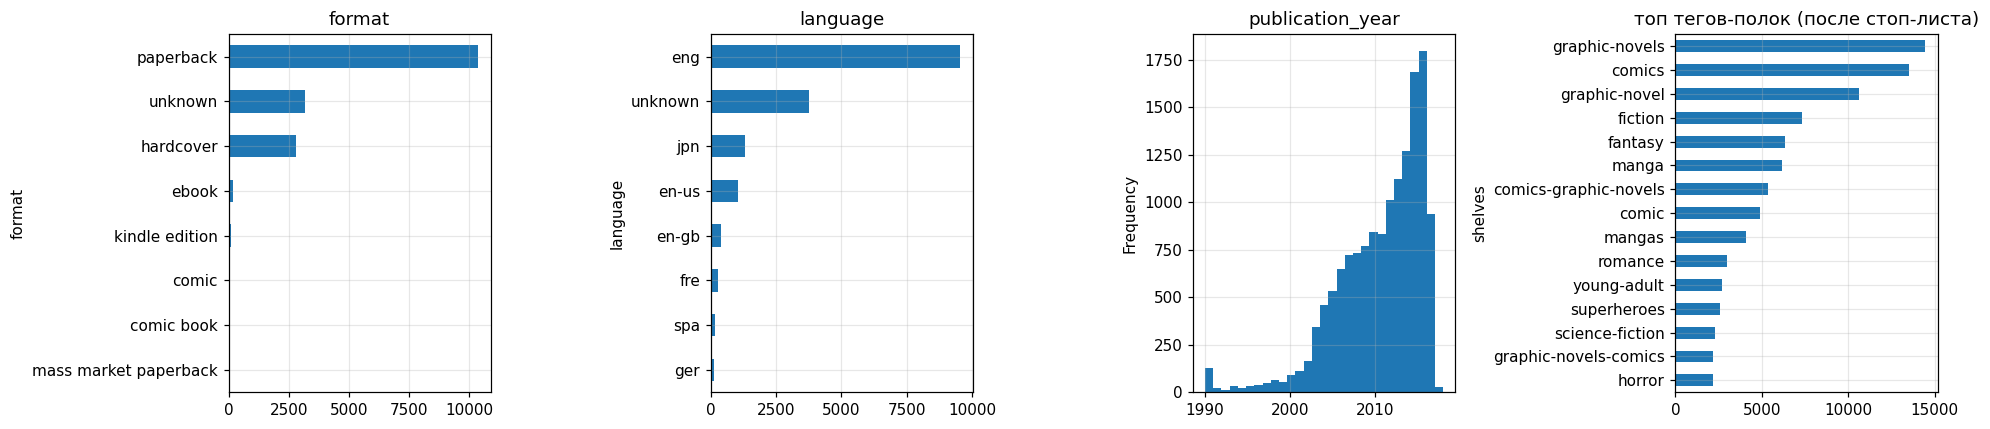

в серии: 68.8%; авторов: 6,872; издателей: 1,324; тегов после стоп-листа: 5,588


In [8]:
meta_items = df.drop_duplicates("item").merge(books, on="book_id", how="left")
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
meta_items["format"].replace("", "unknown").value_counts().head(8).plot.barh(ax=ax[0]); ax[0].set_title("format")
meta_items["language"].replace("", "unknown").value_counts().head(8).plot.barh(ax=ax[1]); ax[1].set_title("language")
meta_items["year"].clip(1990, 2018).plot.hist(bins=29, ax=ax[2]); ax[2].set_title("publication_year")
tags = meta_items["shelves"].apply(lambda sh: [t for t, c in sh if not SHELF_STOP.search(t)][:10]).explode()
tags.value_counts().head(15).plot.barh(ax=ax[3]); ax[3].set_title("топ тегов-полок (после стоп-листа)")
for a in ax: a.invert_yaxis() if a in (ax[0], ax[1], ax[3]) else None
plt.tight_layout(); plt.show()
print(f"в серии: {(meta_items['series'].str.len() > 0).mean():.1%}; "
      f"авторов: {meta_items['authors'].explode().nunique():,}; издателей: {meta_items['publisher'].nunique():,}; "
      f"тегов после стоп-листа: {tags.nunique():,}")

Метаданные богатые: у большинства произведений есть авторы, формат, язык, год, серия (манга и комиксы
выходят томами — сильный сигнал «следующий том»), а пользовательские полки дают жанровые теги
(`manga`, `graphic-novels`, `superheroes`, `marvel`, `dc`, `horror`, …). Служебные полки (`to-read`, `owned`,
`2016-reads`, `kindle`, …) отфильтрованы регулярным выражением `SHELF_STOP`.

Агрегаты `average_rating`, `ratings_count`, `similar_books` в признаки **не берём**: они посчитаны на момент сбора
данных (после test) и содержат утечку. Популярность для FM считаем только по train.

## 3. Протокол оценки

* **Временное разбиение (глобальное).** train: `date_added` < 2017-09-01; validation: сентябрь 2017;
  test: октябрь 2017. Подбор гиперпараметров — обучение на train, оценка на validation. Финал — переобучение
  с выбранными параметрами на train+validation и оценка на test.
* **Кандидаты:** весь каталог произведений, встречавшихся в истории (train или train+val для финала).
  Произведения, впервые появившиеся в целевом периоде, не может порекомендовать ни одна коллаборативная модель —
  их взаимодействия исключаются из ground truth (доля приводится ниже).
* **Пользователи:** все пользователи с историей и хотя бы одним релевантным объектом в целевом периоде —
  одни и те же для всех моделей. Новые (холодные) пользователи не оцениваются: для них в продакшене
  нужен популярностный fallback; их доля приводится ниже.
* **Исключение известного:** всё, что уже есть на полке пользователя в истории, удаляется из кандидатов
  (повторно добавить произведение на Goodreads нельзя).
* **Метрики (K=10).** Основная — **NDCG@10** (выбрана до подбора): учитывает порядок в коротком списке,
  что соответствует ленте из 10 рекомендаций, где верхние позиции видят чаще. Дополнительные —
  **Recall@10** (какая доля будущих добавлений покрыта списком, нормировка на min(|rel|, 10)),
  **HR@10** (доля пользователей, получивших хотя бы одно попадание), **MAP@10**, а также
  **Coverage@10** и **Novelty@10** для контроля перекоса в популярное.

In [9]:
VAL_START, TEST_START, TEST_END = (pd.Timestamp(CONFIG[k], tz="UTC") for k in ("val_start", "test_start", "test_end"))
val_split = make_split(df, VAL_START, TEST_START)     # история = train, цель = validation
test_split = make_split(df, TEST_START, TEST_END)     # история = train + validation, цель = test
ev_val, ev_test = val_split.eval_set(), test_split.eval_set()
summary = pd.DataFrame({
    "история: взаимодействий": [len(val_split.train), len(test_split.train)],
    "пользователей": [val_split.n_users, test_split.n_users], "объектов (кандидаты)": [val_split.n_items, test_split.n_items],
    "цель: взаимодействий": [val_split.stats["target_interactions"], test_split.stats["target_interactions"]],
    "доля строк холодных пользователей": [val_split.stats["share_cold_user_rows"], test_split.stats["share_cold_user_rows"]],
    "доля строк новых объектов": [val_split.stats["share_new_item_rows"], test_split.stats["share_new_item_rows"]],
    "оцениваемых пользователей": [len(ev_val.users), len(ev_test.users)],
    "релевантных на пользователя (среднее)": [np.mean([len(t) for t in ev_val.truth]), np.mean([len(t) for t in ev_test.truth])],
}, index=["validation", "test"]).T
display(summary)

,validation,test
история: взаимодействий,1.727778e+06,1.799821e+06
пользователей,4.050400e+04,4.077100e+04
объектов (кандидаты),1.694900e+04,1.695600e+04
цель: взаимодействий,7.204300e+04,5.527300e+04
доля строк холодных пользователей,1.013700e-01,7.938777e-02
доля строк новых объектов,1.158480e-03,2.456520e-03
оцениваемых пользователей,1.278100e+04,1.128500e+04
релевантных на пользователя (среднее),4.941319e+00,4.395835e+00


In [10]:
def add_pop(split, ev, label):
    res = {}
    for name, w in [("Popularity (вся история)", None), ("Popularity (30 дней)", 30)]:
        m = Popularity(w).fit(split.train["user"].to_numpy(), split.train["item"].to_numpy(), split.train["ts"].to_numpy(), split.n_items)
        res[name] = evaluate(m, ev, k=K)
    return pd.DataFrame(res).T.assign(stage=label)
display(pd.concat([add_pop(val_split, ev_val, "val")]).round(4))

,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec,stage
Popularity (вся история),0.0326,0.0485,0.1036,0.0190,0.0030,8.2900,2.3209,val
Popularity (30 дней),0.0368,0.0543,0.1185,0.0217,0.0021,9.0121,2.2247,val


Популярность — ориентир, а не одна из пяти моделей. Популярность за последние 30 дней заметно сильнее
всей истории: в каталоге комиксов важна свежесть (новые тома выходящих серий).

## 4. Модели и подбор гиперпараметров на validation

Основная метрика подбора — NDCG@10 на validation; test не используется до финального сравнения.
Для каждой модели ниже — постановка, формулы и пространство поиска.

In [11]:
X_val = val_split.matrix()                 # бинарная матрица user x item истории (train)
results_val, best_params = {}, {}
def row_params(row, keys):
    # numpy-скаляры -> python-типы, чтобы параметры можно было передавать в модели и сериализовать
    out = {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items() if k in keys}
    return {k: (int(v) if isinstance(keys[k], int) and not isinstance(keys[k], bool) else v) for k, v in out.items()}
def run_grid(name, fn, grid):
    t0 = time.time()
    res = grid_search(fn, grid, ev_val, metric=METRIC, k=K, verbose=True)
    best_params[name] = row_params(res.iloc[0], grid[0])
    results_val[name] = res
    print(f"{name}: {len(grid)} конфигураций за {time.time() - t0:.0f}s; лучшая: {best_params[name]} -> {METRIC}={res.iloc[0][METRIC]:.4f}")
    return res

### 4.1 Item-based KNN

Сходство — асимметричный косинус со сжатием (shrinkage) на бинарной матрице $X$ (опционально с IUF-весами
пользователей $1/\sqrt{\log(1+|I_u|)}$, понижающими вклад «всеядных» читателей):
$$\mathrm{sim}(i,j)=\frac{x_i^\top x_j}{\|x_i\|^{2\alpha}\,\|x_j\|^{2(1-\alpha)}+\lambda_{shrink}},$$
для каждого целевого $j$ оставляем $k$ ближайших соседей, сходства возводятся в степень $p$ (усиление близких соседей).
Скор: $\hat s_{uj}=\sum_{i\in I_u}r_{ui}\,\mathrm{sim}(i,j)^p$, где профиль пользователя $r_{ui}$ — бинарный
($h=\infty$) или взвешенный по давности $r_{ui}=2^{-\Delta t_{ui}/h}$ ($\Delta t$ — дни от добавления до конца истории):
соседи недавно добавленных книг весят больше (способ формирования рекомендаций, сходства не меняются).
Пространство поиска (поэтапно): $k\in\{20,50,100,200\}$, $\lambda_{shrink}\in\{0,10\}$, $p\in\{1,2\}$ при IUF; затем $\alpha\in\{0.5,0.7\}$, $p=3$, без IUF;
затем $h\in\{\infty,30,90,180,365\}$ дней.

In [12]:
_prof_cache = {}
def profile(split, h):
    # профиль пользователя для формирования рекомендаций: бинарный (h=inf) или по давности
    key = (id(split), h)
    if key not in _prof_cache:
        tr = split.train
        _prof_cache[key] = recency_profile(tr["user"].to_numpy(), tr["item"].to_numpy(), tr["ts"].to_numpy(),
                                           split.t_end, h, split.n_users, split.n_items)
    return _prof_cache[key]

def fit_knn(p, split=val_split):
    p = dict(p); h = p.pop("half_life", np.inf)
    return ItemKNN(**p).fit(split.matrix(), profile=profile(split, h))

grid1 = expand_grid(k=[20, 50, 100, 200], shrink=[0, 10], alpha=[0.5], pow=[1.0, 2.0], iuf=[True], half_life=[np.inf])
r1 = run_grid("ItemKNN", fit_knn, grid1)
b = best_params["ItemKNN"]
grid2 = [{**b, "alpha": 0.7}, {**b, "pow": 3.0}, {**b, "iuf": False}]
r2 = grid_search(fit_knn, grid2, ev_val, metric=METRIC, k=K)
b = row_params(pd.concat([r1, r2]).sort_values(METRIC, ascending=False).iloc[0], grid1[0])
grid3 = [{**b, "half_life": h} for h in (30.0, 90.0, 180.0, 365.0)]
r3 = grid_search(fit_knn, grid3, ev_val, metric=METRIC, k=K)
results_val["ItemKNN"] = pd.concat([r1, r2, r3]).sort_values(METRIC, ascending=False).reset_index(drop=True)
best_params["ItemKNN"] = row_params(results_val["ItemKNN"].iloc[0], grid1[0])
print("best:", best_params["ItemKNN"])
display(results_val["ItemKNN"].head(8).round(4))

{'k': 20, 'shrink': 0, 'alpha': 0.5, 'pow': 1.0, 'iuf': True, 'half_life': inf, 'NDCG@10': np.float64(0.07836), 'Recall@10': np.float64(0.10537), 'fit_sec': 5.0}


{'k': 20, 'shrink': 0, 'alpha': 0.5, 'pow': 2.0, 'iuf': True, 'half_life': inf, 'NDCG@10': np.float64(0.07996), 'Recall@10': np.float64(0.10499), 'fit_sec': 4.4}


{'k': 20, 'shrink': 10, 'alpha': 0.5, 'pow': 1.0, 'iuf': True, 'half_life': inf, 'NDCG@10': np.float64(0.07744), 'Recall@10': np.float64(0.10471), 'fit_sec': 4.4}


{'k': 20, 'shrink': 10, 'alpha': 0.5, 'pow': 2.0, 'iuf': True, 'half_life': inf, 'NDCG@10': np.float64(0.07914), 'Recall@10': np.float64(0.10569), 'fit_sec': 4.3}


{'k': 50, 'shrink': 0, 'alpha': 0.5, 'pow': 1.0, 'iuf': True, 'half_life': inf, 'NDCG@10': np.float64(0.07557), 'Recall@10': np.float64(0.10064), 'fit_sec': 4.4}


{'k': 50, 'shrink': 0, 'alpha': 0.5, 'pow': 2.0, 'iuf': True, 'half_life': inf, 'NDCG@10': np.float64(0.07958), 'Recall@10': np.float64(0.10271), 'fit_sec': 4.3}


... (16 outputs left out)

{'k': 20, 'shrink': 0, 'alpha': 0.5, 'pow': 2.0, 'iuf': True, 'half_life': 180.0, 'NDCG@10': np.float64(0.10003), 'Recall@10': np.float64(0.12661), 'fit_sec': 4.9}


{'k': 20, 'shrink': 0, 'alpha': 0.5, 'pow': 2.0, 'iuf': True, 'half_life': 365.0, 'NDCG@10': np.float64(0.09145), 'Recall@10': np.float64(0.11753), 'fit_sec': 4.9}


best: {'k': 20, 'shrink': 0, 'alpha': 0.5, 'pow': 2.0, 'iuf': True, 'half_life': 30.0}


,k,shrink,alpha,pow,iuf,half_life,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec,fit_sec
0,20,0,0.5,2.0,True,30.0,0.1096,0.1298,0.2278,0.0838,0.7641,12.6682,3.3656,4.9728
1,20,0,0.5,2.0,True,90.0,0.1072,0.1321,0.2338,0.0802,0.6949,12.5300,3.3391,4.9235
2,20,0,0.5,2.0,True,180.0,0.1000,0.1266,0.2251,0.0735,0.6629,12.4460,3.3490,4.8987
3,20,0,0.5,2.0,True,365.0,0.0915,0.1175,0.2104,0.0663,0.6515,12.3941,3.2914,4.8766
4,20,0,0.5,2.0,True,inf,0.0800,0.1050,0.1933,0.0571,0.6471,12.3465,3.2490,4.4352
5,20,0,0.5,3.0,True,inf,0.0797,0.1037,0.1885,0.0572,0.6405,12.4905,3.2751,4.3925
6,20,0,0.5,2.0,False,inf,0.0796,0.1041,0.1920,0.0570,0.6511,12.3047,3.2652,4.3346
7,50,0,0.5,2.0,True,inf,0.0796,0.1027,0.1887,0.0574,0.6334,12.2191,3.5724,4.3104


### 4.2 iALS (неявная обратная связь)

Hu, Koren, Volinsky (2008): по всем парам $(u,i)$ минимизируем взвешенную квадратичную ошибку, наблюдаемым
парам ставим цель $p_{ui}=1$ и уверенность $c_{ui}=1+\alpha r_{ui}$ ($r_{ui}=1$ — бинарный сигнал), ненаблюдаемым — $p=0$, $c=w_0=1$:
$$L=\sum_{(u,i)\in S}c_{ui}(p_{ui}-x_u^\top y_i)^2+w_0\!\!\sum_{(u,i)\notin S}(x_u^\top y_i)^2+\sum_u\lambda_u\|x_u\|^2+\sum_i\lambda_i\|y_i\|^2,$$
регуляризация, масштабируемая частотой (Rendle et al., *Revisiting the Performance of iALS*, 2022):
$\lambda_u=\lambda\,(|S_u|+w_0|I|)^{\nu}$. Шаг ALS для пользователя:
$$\Big(w_0Y^\top Y+\sum_{i\in S_u}(c_{ui}-w_0)\,y_iy_i^\top+\lambda_uI\Big)x_u=\sum_{i\in S_u}c_{ui}p_{ui}\,y_i,$$
системы всех пользователей решаются одновременно 3 шагами сопряжённых градиентов с тёплым стартом
(одно умножение — $O(\mathrm{nnz}\cdot f)$), затем симметрично для объектов. Скор: $x_u^\top y_i$.
Пространство поиска: $f\in\{128,256,512\}$, $\alpha\in\{1,5,20\}$, $\nu\in\{0,1\}$ с соответствующими сетками $\lambda$, 15 итераций.

In [13]:
grid = (expand_grid(factors=[128], alpha=[1.0, 5.0, 20.0], reg_exp=[0.0], reg=[1.0, 10.0, 100.0]) +
        expand_grid(factors=[128], alpha=[1.0, 5.0, 20.0], reg_exp=[1.0], reg=[1e-4, 1e-3, 1e-2]))
r = run_grid("iALS", lambda p: IALS(**p, iterations=15, seed=SEED).fit(X_val), grid)
b = best_params["iALS"]
grid2 = expand_grid(factors=[256, 512], alpha=[b["alpha"]], reg_exp=[b["reg_exp"]], reg=[b["reg"]])
r2 = grid_search(lambda p: IALS(**p, iterations=15, seed=SEED).fit(X_val), grid2, ev_val, metric=METRIC, k=K)
results_val["iALS"] = pd.concat([r, r2]).sort_values(METRIC, ascending=False).reset_index(drop=True)
best_params["iALS"] = row_params(results_val["iALS"].iloc[0], grid[0])
print("best:", best_params["iALS"])
display(results_val["iALS"].head(8).round(4))

{'factors': 128, 'alpha': 1.0, 'reg_exp': 0.0, 'reg': 1.0, 'NDCG@10': np.float64(0.06418), 'Recall@10': np.float64(0.09035), 'fit_sec': 5.3}


{'factors': 128, 'alpha': 1.0, 'reg_exp': 0.0, 'reg': 10.0, 'NDCG@10': np.float64(0.0643), 'Recall@10': np.float64(0.09052), 'fit_sec': 5.3}


{'factors': 128, 'alpha': 1.0, 'reg_exp': 0.0, 'reg': 100.0, 'NDCG@10': np.float64(0.05459), 'Recall@10': np.float64(0.07608), 'fit_sec': 5.3}


{'factors': 128, 'alpha': 5.0, 'reg_exp': 0.0, 'reg': 1.0, 'NDCG@10': np.float64(0.06308), 'Recall@10': np.float64(0.09214), 'fit_sec': 5.2}


{'factors': 128, 'alpha': 5.0, 'reg_exp': 0.0, 'reg': 10.0, 'NDCG@10': np.float64(0.06307), 'Recall@10': np.float64(0.09191), 'fit_sec': 5.2}


{'factors': 128, 'alpha': 5.0, 'reg_exp': 0.0, 'reg': 100.0, 'NDCG@10': np.float64(0.06454), 'Recall@10': np.float64(0.09188), 'fit_sec': 5.2}


... (13 outputs left out)

{'factors': 256, 'alpha': 1.0, 'reg_exp': 1.0, 'reg': 0.001, 'NDCG@10': np.float64(0.07036), 'Recall@10': np.float64(0.09879), 'fit_sec': 10.3}


{'factors': 512, 'alpha': 1.0, 'reg_exp': 1.0, 'reg': 0.001, 'NDCG@10': np.float64(0.07693), 'Recall@10': np.float64(0.10895), 'fit_sec': 20.8}


best: {'factors': 512, 'alpha': 1.0, 'reg_exp': 1.0, 'reg': 0.001}


,factors,alpha,reg_exp,reg,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec,fit_sec
0,512,1.0,1.0,0.0010,0.0769,0.1090,0.2085,0.0515,0.3386,11.7126,6.9699,20.8135
1,256,1.0,1.0,0.0010,0.0704,0.0988,0.1936,0.0470,0.2516,11.2390,5.0067,10.3158
2,128,1.0,1.0,0.0010,0.0647,0.0903,0.1802,0.0431,0.1781,10.7036,4.0501,5.2818
3,128,5.0,0.0,100.0000,0.0645,0.0919,0.1839,0.0423,0.1823,10.4118,4.0276,5.1875
4,128,1.0,0.0,10.0000,0.0643,0.0905,0.1801,0.0427,0.1848,10.7947,4.0186,5.2978
5,128,1.0,1.0,0.0001,0.0643,0.0905,0.1798,0.0427,0.1873,10.8133,4.0609,5.2808
6,128,1.0,0.0,1.0000,0.0642,0.0904,0.1793,0.0427,0.1882,10.8187,4.0509,5.3161
7,128,5.0,1.0,0.0010,0.0633,0.0916,0.1827,0.0411,0.2139,10.6864,4.0605,5.2093


### 4.3 EASE

Steck (2019): линейный автоэнкодер item-item без скрытого слоя
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2\quad\text{s.t. }\operatorname{diag}(B)=0,$$
решение в замкнутой форме: $P=(X^\top X+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$ ($i\neq j$), $B_{jj}=0$; скор $\hat s_u=x_uB$.
Гиперпараметр обучения — $\lambda\in\{50,100,200,400,800,1600,3200\}$; при формировании рекомендаций, как и в ItemKNN,
профиль $x_u$ может быть взвешен по давности, $h\in\{\infty,30,90,180,365\}$ дней ($B$ не меняется).

{'reg': 50.0, 'half_life': inf, 'NDCG@10': np.float64(0.08131), 'Recall@10': np.float64(0.12292), 'fit_sec': 9.8}


{'reg': 100.0, 'half_life': inf, 'NDCG@10': np.float64(0.0829), 'Recall@10': np.float64(0.12501), 'fit_sec': 9.9}


{'reg': 200.0, 'half_life': inf, 'NDCG@10': np.float64(0.08314), 'Recall@10': np.float64(0.12363), 'fit_sec': 9.9}


{'reg': 400.0, 'half_life': inf, 'NDCG@10': np.float64(0.08276), 'Recall@10': np.float64(0.12115), 'fit_sec': 9.9}


{'reg': 800.0, 'half_life': inf, 'NDCG@10': np.float64(0.08196), 'Recall@10': np.float64(0.1191), 'fit_sec': 10.2}


{'reg': 1600.0, 'half_life': inf, 'NDCG@10': np.float64(0.07808), 'Recall@10': np.float64(0.11284), 'fit_sec': 10.1}


... (12 outputs left out)

{'reg': 400.0, 'half_life': 180.0, 'NDCG@10': np.float64(0.10911), 'Recall@10': np.float64(0.15), 'fit_sec': 10.2}


{'reg': 400.0, 'half_life': 365.0, 'NDCG@10': np.float64(0.10004), 'Recall@10': np.float64(0.14214), 'fit_sec': 10.3}


best: {'reg': 200.0, 'half_life': 90.0}


,reg,half_life,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec,fit_sec
0,200.0,90.0,0.1162,0.1538,0.2875,0.0809,0.5478,11.3920,3.5850,9.9635
1,100.0,90.0,0.1157,0.1523,0.2880,0.0804,0.5862,11.4831,3.6420,9.9363
2,400.0,90.0,0.1146,0.1516,0.2839,0.0799,0.4995,11.2378,3.7926,10.1416
3,100.0,180.0,0.1123,0.1537,0.2949,0.0754,0.5646,11.3342,3.6444,9.9496
4,200.0,30.0,0.1121,0.1407,0.2627,0.0810,0.5937,11.6028,3.6397,9.9348
5,200.0,180.0,0.1117,0.1529,0.2914,0.0752,0.5167,11.2144,3.6550,10.0604
6,400.0,30.0,0.1114,0.1404,0.2602,0.0806,0.5599,11.5218,3.7458,10.2600
7,100.0,30.0,0.1114,0.1391,0.2627,0.0802,0.6164,11.6173,3.5998,10.0417


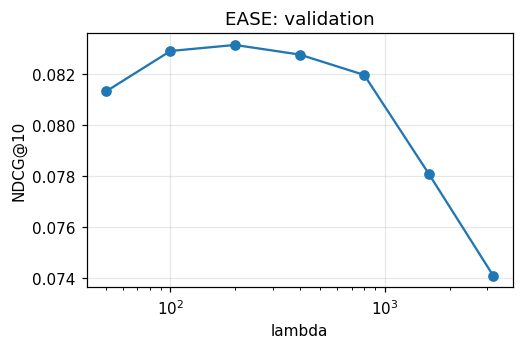

In [14]:
grid = expand_grid(reg=[50.0, 100.0, 200.0, 400.0, 800.0, 1600.0, 3200.0])
def fit_ease(p, split=val_split):
    p = dict(p); h = p.pop("half_life", np.inf)
    return EASE(**p).fit(split.matrix(), profile=profile(split, h))
grid = expand_grid(reg=[50.0, 100.0, 200.0, 400.0, 800.0, 1600.0, 3200.0], half_life=[np.inf])
r = run_grid("EASE", fit_ease, grid)
rr = r.sort_values("reg")
b = best_params["EASE"]
grid2 = expand_grid(reg=[b["reg"] / 2, b["reg"], b["reg"] * 2], half_life=[30.0, 90.0, 180.0, 365.0])
r2 = grid_search(fit_ease, grid2, ev_val, metric=METRIC, k=K)
results_val["EASE"] = pd.concat([r, r2]).sort_values(METRIC, ascending=False).reset_index(drop=True)
best_params["EASE"] = row_params(results_val["EASE"].iloc[0], grid[0])
print("best:", best_params["EASE"])
display(results_val["EASE"].head(8).round(4))
plt.figure(figsize=(5, 3)); plt.semilogx(rr["reg"], rr[METRIC], "o-"); plt.xlabel("lambda"); plt.ylabel(METRIC); plt.title("EASE: validation"); plt.show()

### 4.4 Factorization Machine с метапризнаками

Пара (пользователь, произведение) описывается разреженным вектором $x=[x^U;x^I]$:

| сторона | поле | обоснование |
|---|---|---|
| пользователь | `user_id` | индивидуальное смещение вкуса |
| пользователь | мешок последних 200 произведений истории (веса $1/\sqrt{n}$) | вкус через то, что уже прочитано (как в SVD++/FISM); доступно в момент рекомендации |
| пользователь | активность, доля оценённого, средняя оценка, давность последнего действия (бакеты по train) | «читатель-коллекционер» vs эпизодический |
| произведение | `item_id` | коллаборативная часть |
| произведение | авторы, серия, издатель | комиксы читают сериями, у издателей/авторов есть свои аудитории |
| произведение | теги-полки (жанры), формат, язык, год, число страниц, e-book, «в серии» | контентное сходство, помогает редким объектам |
| произведение | популярность за всю историю и за последние 30 дней (бакеты по train) | тренды; считается только по прошлому |

Модель второго порядка
$$\hat y(x)=w_0+\sum_j w_jx_j+\tfrac12\sum_f\Big[\big(\textstyle\sum_j v_{jf}x_j\big)^2-\sum_j v_{jf}^2x_j^2\Big].$$
Разбив суммы на пользовательскую и объектную части ($s_u=\sum_{j\in U}v_jx_j$, $s_i=\sum_{j\in I}v_jx_j$):
$\hat y(u,i)=\mathrm{const}_u+\mathrm{lin}(i)+\mathrm{pair}(i)+\langle s_u,s_i\rangle$, поэтому скоринг всего каталога —
одно матричное произведение. Обучение: на каждый батч наблюдаемых пар сэмплируем $n_{neg}=1024$ общих равномерных негатива (объектная часть считается один раз на батч) и минимизируем
sampled softmax $-\log\frac{e^{\hat y(u,i^+)}}{e^{\hat y(u,i^+)}+\sum_n e^{\hat y(u,i^-_n)}}$ (или BPR) + $L_2$; целевой объект
исключается из мешка истории (leave-one-out контекст, иначе модель выучила бы «объект предсказывает сам себя»).
Пространство поиска: $f\in\{64,128\}$, lr ∈ {5e-4, 1e-3}, $L_2$ ∈ {0, 1e-2, 1e-1}, функция потерь ∈ {softmax, BPR}, эпох 5–20 (в предварительном запуске lr=3e-3 заметно переобучался); плюс абляция наборов признаков.

In [15]:
fb = FeatureBuilder()
def fm_inputs(split, use_meta=True, use_hist=True, use_user_id=True):
    ib = fb.item_blocks(split, books); ub = fb.user_blocks(split)
    item_names = ["item_id"] + (["author", "series", "tags", "publisher", "format", "language", "year", "pages", "flags", "pop", "recent_pop"] if use_meta else [])
    user_names = (["user_id"] if use_user_id else []) + (["activity", "rated_share", "mean_rating", "recency"] if use_meta else [])
    hist = fb.history_bag(split) if use_hist else None
    return stack_blocks(ub, user_names), stack_blocks(ib, item_names), hist

fm_val_inputs = {meta: fm_inputs(val_split, use_meta=meta) for meta in (True, False)}
uf, itf, hist = fm_val_inputs[True]
print("user features:", uf.shape, "item features:", itf.shape, "history bag:", hist.shape, "nnz/user:", hist.nnz / hist.shape[0])

def fit_fm(p, split=val_split, inputs=None):
    p = dict(p); meta = p.pop("meta", True)
    uf, itf, hist = inputs if inputs is not None else fm_val_inputs[meta]
    return FM(**p, n_neg=1024, batch_size=4096, seed=SEED).fit(split.matrix(), uf, itf, hist)

grid = expand_grid(meta=[True], factors=[64, 128], lr=[5e-4, 1e-3], reg=[0.0, 1e-2], loss=["softmax"], epochs=[10])
r = run_grid("FM", fit_fm, grid)
b = best_params["FM"]
grid2 = [{**b, "loss": "bpr"}, {**b, "epochs": 5}, {**b, "epochs": 20}, {**b, "reg": 1e-1}]
r2 = grid_search(fit_fm, grid2, ev_val, metric=METRIC, k=K)
results_val["FM"] = pd.concat([r, r2]).sort_values(METRIC, ascending=False).reset_index(drop=True)
best_params["FM"] = row_params(results_val["FM"].iloc[0], grid[0])
print("best:", best_params["FM"])
display(results_val["FM"].head(8).round(4))

user features: (40504, 40530) item features: (16949, 20941) history bag: (40504, 16949) nnz/user: 37.80530317993285


{'meta': True, 'factors': 64, 'lr': 0.0005, 'reg': 0.0, 'loss': 'softmax', 'epochs': 10, 'NDCG@10': np.float64(0.06034), 'Recall@10': np.float64(0.08966), 'fit_sec': 93.0}


{'meta': True, 'factors': 64, 'lr': 0.0005, 'reg': 0.01, 'loss': 'softmax', 'epochs': 10, 'NDCG@10': np.float64(0.05907), 'Recall@10': np.float64(0.08716), 'fit_sec': 91.3}


{'meta': True, 'factors': 64, 'lr': 0.001, 'reg': 0.0, 'loss': 'softmax', 'epochs': 10, 'NDCG@10': np.float64(0.06142), 'Recall@10': np.float64(0.0917), 'fit_sec': 91.2}


{'meta': True, 'factors': 64, 'lr': 0.001, 'reg': 0.01, 'loss': 'softmax', 'epochs': 10, 'NDCG@10': np.float64(0.06029), 'Recall@10': np.float64(0.08986), 'fit_sec': 91.2}


{'meta': True, 'factors': 128, 'lr': 0.0005, 'reg': 0.0, 'loss': 'softmax', 'epochs': 10, 'NDCG@10': np.float64(0.05953), 'Recall@10': np.float64(0.08791), 'fit_sec': 140.6}


... (6 outputs left out)

{'meta': True, 'factors': 64, 'lr': 0.001, 'reg': 0.0, 'loss': 'softmax', 'epochs': 20, 'NDCG@10': np.float64(0.05936), 'Recall@10': np.float64(0.0878), 'fit_sec': 181.7}


{'meta': True, 'factors': 64, 'lr': 0.001, 'reg': 0.1, 'loss': 'softmax', 'epochs': 10, 'NDCG@10': np.float64(0.04743), 'Recall@10': np.float64(0.07176), 'fit_sec': 91.1}


best: {'meta': True, 'factors': 64, 'lr': 0.001, 'reg': 0.0, 'loss': 'softmax', 'epochs': 10}


,meta,factors,lr,reg,loss,epochs,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec,fit_sec
0,True,64,0.0010,0.00,softmax,10,0.0614,0.0917,0.1872,0.0381,0.5571,11.3719,3.1853,91.2486
1,True,64,0.0005,0.00,softmax,10,0.0603,0.0897,0.1864,0.0372,0.4752,10.7555,3.1239,92.9944
2,True,64,0.0010,0.01,softmax,10,0.0603,0.0899,0.1875,0.0371,0.4790,11.0718,3.1217,91.2103
3,True,128,0.0010,0.00,softmax,10,0.0596,0.0894,0.1842,0.0369,0.5650,11.5320,3.0783,140.5133
4,True,128,0.0005,0.00,softmax,10,0.0595,0.0879,0.1827,0.0371,0.5160,11.1533,3.2117,140.6378
5,True,64,0.0010,0.00,softmax,20,0.0594,0.0878,0.1836,0.0371,0.5416,11.3785,3.0659,181.7084
6,True,64,0.0005,0.01,softmax,10,0.0591,0.0872,0.1825,0.0366,0.4155,10.6098,3.1024,91.3039
7,True,128,0.0005,0.01,softmax,10,0.0585,0.0879,0.1818,0.0359,0.4527,10.9147,3.1229,140.5714


**Абляция признаков FM** (лучшие гиперпараметры, validation): что дают метаданные и мешок истории.

In [16]:
abl = []
for name, kw in [("ID + история + метаданные", dict(use_meta=True)), ("ID + история (без метаданных)", dict(use_meta=False)),
                 ("ID + метаданные (без истории)", dict(use_meta=True, use_hist=False)), ("только ID (MF)", dict(use_meta=False, use_hist=False))]:
    inputs = fm_val_inputs[kw["use_meta"]] if kw.get("use_hist", True) else fm_inputs(val_split, **kw)
    p = {k: v for k, v in best_params["FM"].items() if k != "meta"}
    m = FM(**p, n_neg=1024, batch_size=4096, seed=SEED).fit(val_split.matrix(), *inputs)
    abl.append({"признаки": name, **evaluate(m, ev_val, k=K)})
    del m
fm_ablation = pd.DataFrame(abl).set_index("признаки")
display(fm_ablation.round(4))

,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec
признаки,,,,,,,
ID + история + метаданные,0.0614,0.0917,0.1872,0.0381,0.5571,11.3719,3.0922
ID + история (без метаданных),0.0613,0.0896,0.1881,0.0383,0.4713,10.6758,3.1095
ID + метаданные (без истории),0.0488,0.0750,0.1650,0.0284,0.3473,10.6245,3.0908
только ID (MF),0.0516,0.0749,0.1609,0.0320,0.2896,10.1829,3.0534


### 4.5 iALS с собственным целевым сигналом

Базовый iALS регрессирует каждую наблюдаемую пару в одно и то же $p_{ui}=1$. Предлагаемый таргет
использует то, *что* и *когда* пользователь сказал о книге ($r_{ui}$ — звёзды, 0 = без оценки; $\Delta t_{ui}$ — дни от
добавления до конца истории):
$$g(r)=\begin{cases}0,& r\in\{1,2\}\ \text{(явный негатив)}\\ \max\!\big(0,\,1+\gamma\frac{r-3.5}{1.5}\big),& r\in\{3,4,5\}\\ 1,& r=0\end{cases}\qquad
d(\Delta t)=\beta+(1-\beta)\,2^{-\Delta t/h},\qquad p_{ui}=g(r_{ui})\,d(\Delta t_{ui}).$$

* **Давность** $d$: вкусы в комиксах дрейфуют (серии заканчиваются, выходят новые тома), а предсказываем мы
  ближайший месяц — недавнее добавление должно сильнее тянуть $x_u$ к $y_i$. Пол $\beta$ не даёт забыть давнюю историю полностью.
* **Оценка** $g$: «it was amazing» (5) — сильнее, чем «liked it» (3); 1–2 звезды остаются *наблюдаемой* парой с целью 0 и
  уверенностью $1+\alpha$, т.е. становятся уверенным негативом, а не просто «неизвестным».
* Уверенность та же, что в базовом iALS ($c_{ui}=1+\alpha$), решатель и функция потерь общие — отличается **только цель** $p_{ui}$.
  При $\gamma=0$, $\beta=1$ и без правила дизлайков модель совпадает с базовым iALS.

Гиперпараметры факторизации ($f,\alpha,\lambda,\nu$) берём лучшие у базового iALS (чтобы сравнение было честным),
подбираем только параметры таргета: $h\in\{30,90,180,365\}$ дней, $\beta\in\{0.1,0.3,0.6\}$, $\gamma\in\{0,0.5,1\}$.
Затем — абляция компонентов по тому же протоколу.

In [17]:
base = best_params["iALS"]
def fit_custom(p, split=val_split):
    return CustomTargetIALS(**base, **p, iterations=15, seed=SEED).fit(split.train, split.n_users, split.n_items, t_end=split.t_end)

grid = expand_grid(half_life_days=[30.0, 90.0, 180.0, 365.0], beta=[0.1, 0.3, 0.6], gamma=[0.5], dislike_zero=[True])
r = run_grid("iALS-custom", fit_custom, grid)
b = best_params["iALS-custom"]
grid2 = expand_grid(half_life_days=[b["half_life_days"]], beta=[b["beta"]], gamma=[0.0, 1.0], dislike_zero=[True])
r2 = grid_search(fit_custom, grid2, ev_val, metric=METRIC, k=K)
results_val["iALS-custom"] = pd.concat([r, r2]).sort_values(METRIC, ascending=False).reset_index(drop=True)
best_params["iALS-custom"] = row_params(results_val["iALS-custom"].iloc[0], grid[0])
print("best:", best_params["iALS-custom"])
display(results_val["iALS-custom"].head(8).round(4))

{'half_life_days': 30.0, 'beta': 0.1, 'gamma': 0.5, 'dislike_zero': True, 'NDCG@10': np.float64(0.07489), 'Recall@10': np.float64(0.10127), 'fit_sec': 20.9}


{'half_life_days': 30.0, 'beta': 0.3, 'gamma': 0.5, 'dislike_zero': True, 'NDCG@10': np.float64(0.08795), 'Recall@10': np.float64(0.1185), 'fit_sec': 21.0}


{'half_life_days': 30.0, 'beta': 0.6, 'gamma': 0.5, 'dislike_zero': True, 'NDCG@10': np.float64(0.09041), 'Recall@10': np.float64(0.123), 'fit_sec': 20.9}


{'half_life_days': 90.0, 'beta': 0.1, 'gamma': 0.5, 'dislike_zero': True, 'NDCG@10': np.float64(0.09734), 'Recall@10': np.float64(0.12791), 'fit_sec': 21.0}


{'half_life_days': 90.0, 'beta': 0.3, 'gamma': 0.5, 'dislike_zero': True, 'NDCG@10': np.float64(0.0984), 'Recall@10': np.float64(0.13094), 'fit_sec': 21.0}


{'half_life_days': 90.0, 'beta': 0.6, 'gamma': 0.5, 'dislike_zero': True, 'NDCG@10': np.float64(0.09313), 'Recall@10': np.float64(0.12643), 'fit_sec': 20.9}


... (7 outputs left out)

{'half_life_days': 180.0, 'beta': 0.1, 'gamma': 0.0, 'dislike_zero': True, 'NDCG@10': np.float64(0.09594), 'Recall@10': np.float64(0.1284), 'fit_sec': 20.9}


{'half_life_days': 180.0, 'beta': 0.1, 'gamma': 1.0, 'dislike_zero': True, 'NDCG@10': np.float64(0.10484), 'Recall@10': np.float64(0.13643), 'fit_sec': 20.9}


best: {'half_life_days': 180.0, 'beta': 0.1, 'gamma': 1.0, 'dislike_zero': True}


,half_life_days,beta,gamma,dislike_zero,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec,fit_sec
0,180.0,0.1,1.0,True,0.1048,0.1364,0.2567,0.0739,0.2587,11.2689,6.9946,20.9490
1,180.0,0.1,0.5,True,0.1019,0.1345,0.2553,0.0711,0.2258,11.0120,7.0674,20.9436
2,180.0,0.3,0.5,True,0.0997,0.1326,0.2512,0.0695,0.2729,11.2404,6.9054,20.9464
3,90.0,0.3,0.5,True,0.0984,0.1309,0.2493,0.0684,0.2151,10.8656,6.9641,20.9555
4,365.0,0.1,0.5,True,0.0983,0.1311,0.2479,0.0683,0.2962,11.4009,6.9092,20.8905
5,90.0,0.1,0.5,True,0.0973,0.1279,0.2483,0.0677,0.1413,10.5454,6.8982,20.9611
6,180.0,0.1,0.0,True,0.0959,0.1284,0.2458,0.0662,0.1913,10.7602,6.9779,20.9345
7,365.0,0.3,0.5,True,0.0938,0.1265,0.2399,0.0646,0.3120,11.5239,6.9647,20.9418


,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,eval_sec
базовый iALS (p=1),0.0769,0.1090,0.2085,0.0515,0.3386,11.7126,6.9679
только давность d(Δt),0.0955,0.1277,0.2446,0.0660,0.1964,10.7766,6.8874
только оценка g(r),0.0815,0.1130,0.2124,0.0553,0.3580,11.9195,6.9419
полный таргет g(r)·d(Δt),0.1048,0.1364,0.2567,0.0739,0.2587,11.2689,6.8902


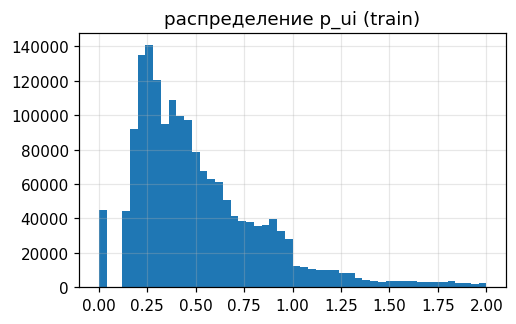

In [18]:
bc = best_params["iALS-custom"]
variants = {
    "базовый iALS (p=1)": dict(half_life_days=np.inf, beta=1.0, gamma=0.0, dislike_zero=False),
    "только давность d(Δt)": dict(half_life_days=bc["half_life_days"], beta=bc["beta"], gamma=0.0, dislike_zero=False),
    "только оценка g(r)": dict(half_life_days=np.inf, beta=1.0, gamma=bc["gamma"], dislike_zero=True),
    "полный таргет g(r)·d(Δt)": bc,
}
custom_ablation = pd.DataFrame({k: evaluate(fit_custom(v), ev_val, k=K) for k, v in variants.items()}).T
display(custom_ablation.round(4))

t = custom_target(val_split.train["rating"].to_numpy(), val_split.train["ts"].to_numpy(), val_split.t_end,
                  bc["gamma"], bc["half_life_days"], bc["beta"], True)
plt.figure(figsize=(5, 3)); plt.hist(t, bins=50); plt.title("распределение p_ui (train)"); plt.show()

## 5. Финальное сравнение на test

Каждая модель переобучается с выбранными на validation параметрами на train+validation (история до 2017-10-01)
и оценивается на октябре 2017: одинаковые пользователи, кандидаты, правило исключения и критерий релевантности.

In [19]:
X_test = test_split.matrix()
fm_test_inputs = fm_inputs(test_split, use_meta=bool(best_params["FM"].get("meta", True)))
final_models = {
    "ItemKNN": lambda: fit_knn(best_params["ItemKNN"], split=test_split),
    "iALS": lambda: IALS(**best_params["iALS"], iterations=15, seed=SEED).fit(X_test),
    "EASE": lambda: fit_ease(best_params["EASE"], split=test_split),
    "FM (meta)": lambda: fit_fm(best_params["FM"], split=test_split, inputs=fm_test_inputs),
    "iALS-custom": lambda: fit_custom(best_params["iALS-custom"], split=test_split),
}
test_rows, test_recs = {}, {}
for name, build in final_models.items():
    set_seed(SEED); t0 = time.time()
    model = build(); fit_sec = time.time() - t0
    res, recs = evaluate(model, ev_test, k=K, return_recs=True)
    test_rows[name] = {**res, "fit_sec": fit_sec}; test_recs[name] = recs
    print(f"{name:12s} {METRIC}={res[METRIC]:.4f}  Recall@10={res['Recall@10']:.4f}  fit {fit_sec:.0f}s", flush=True)
    del model
for name, w in [("Popularity (30 дней)", 30)]:
    m = Popularity(w).fit(test_split.train["user"].to_numpy(), test_split.train["item"].to_numpy(), test_split.train["ts"].to_numpy(), test_split.n_items)
    res, recs = evaluate(m, ev_test, k=K, return_recs=True); test_rows[name] = res; test_recs[name] = recs

ItemKNN      NDCG@10=0.1039  Recall@10=0.1249  fit 5s


iALS         NDCG@10=0.0720  Recall@10=0.1004  fit 22s


EASE         NDCG@10=0.1107  Recall@10=0.1472  fit 11s


FM (meta)    NDCG@10=0.0526  Recall@10=0.0794  fit 95s


iALS-custom  NDCG@10=0.1025  Recall@10=0.1331  fit 22s


In [20]:
param_name = {"ItemKNN": "ItemKNN", "iALS": "iALS", "EASE": "EASE", "FM (meta)": "FM", "iALS-custom": "iALS-custom"}
table = pd.DataFrame(test_rows).T
table["val " + METRIC] = [results_val[param_name[n]].iloc[0][METRIC] if n in param_name else np.nan for n in table.index]
table["гиперпараметры"] = [json.dumps({k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in best_params[param_name[n]].items()}, default=str)
                           if n in param_name else "окно 30 дней" for n in table.index]
cols = ["NDCG@10", "Recall@10", "HR@10", "MAP@10", "Coverage@10", "Novelty@10", "val " + METRIC, "fit_sec", "гиперпараметры"]
table = table[cols].sort_values("NDCG@10", ascending=False)
display(table.style.format({c: "{:.4f}" for c in cols[:7]} | {"fit_sec": "{:.0f}"}).background_gradient(subset=["NDCG@10", "Recall@10"], cmap="Greens"))

,NDCG@10,Recall@10,HR@10,MAP@10,Coverage@10,Novelty@10,val NDCG@10,fit_sec,гиперпараметры
EASE,0.1107,0.1472,0.2730,0.0775,0.5373,11.4667,0.1162,11,"{""reg"": 200.0, ""half_life"": 90.0}"
ItemKNN,0.1039,0.1249,0.2144,0.0796,0.7506,12.7277,0.1096,5,"{""k"": 20, ""shrink"": 0, ""alpha"": 0.5, ""pow"": 2.0, ""iuf"": true, ""half_life"": 30.0}"
iALS-custom,0.1025,0.1331,0.2480,0.0727,0.2460,11.2723,0.1048,22,"{""half_life_days"": 180.0, ""beta"": 0.1, ""gamma"": 1.0, ""dislike_zero"": true}"
iALS,0.0720,0.1004,0.1903,0.0489,0.3316,11.7450,0.0769,22,"{""factors"": 512, ""alpha"": 1.0, ""reg_exp"": 1.0, ""reg"": 0.001}"
FM (meta),0.0526,0.0794,0.1664,0.0322,0.4937,11.0359,0.0614,95,"{""meta"": true, ""factors"": 64, ""lr"": 0.001, ""reg"": 0.0, ""loss"": ""softmax"", ""epochs"": 10}"
Popularity (30 дней),0.0325,0.0494,0.1132,0.0191,0.0018,10.3810,nan,nan,окно 30 дней


,сравнение,ΔNDCG@10,95% ДИ,P(Δ ≤ 0)
0,EASE − ItemKNN,0.0068,"[0.0043, 0.0092]",0.0
1,EASE − iALS-custom,0.0082,"[0.0053, 0.0112]",0.0
2,EASE − iALS,0.0387,"[0.0356, 0.0420]",0.0
3,EASE − FM (meta),0.0581,"[0.0542, 0.0621]",0.0
4,EASE − Popularity (30 дней),0.0782,"[0.0735, 0.0829]",0.0


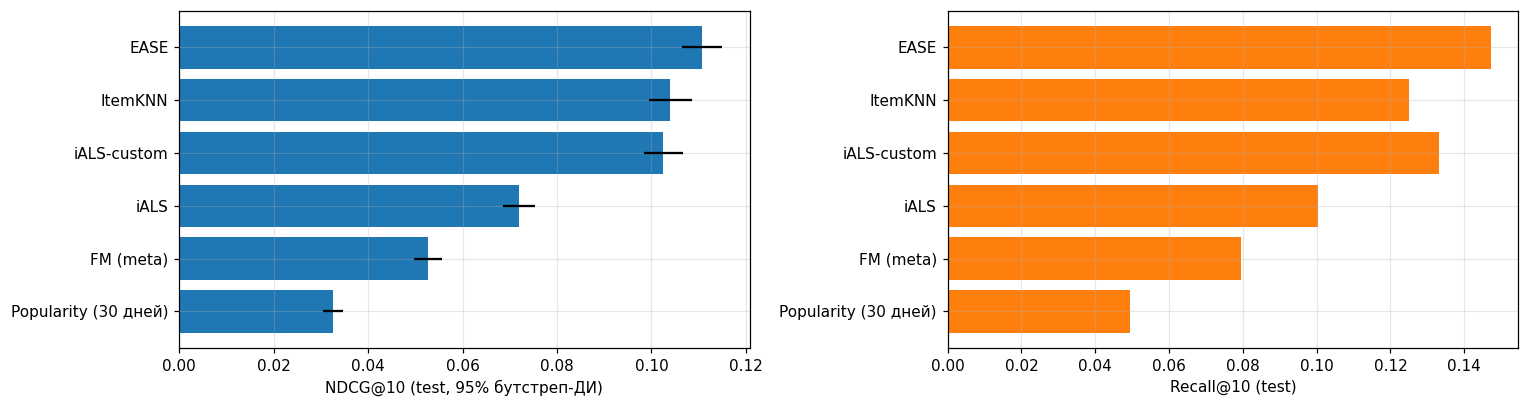

In [21]:
# Надёжность различий: парный бутстреп по пользователям (2000 повторов)
nd = {n: per_user_ndcg(test_recs[n], ev_test.truth, K) for n in test_recs}
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(ev_test.users), size=(2000, len(ev_test.users)))
order = table.index.tolist()
best = order[0]
rows = []
for other in order[1:]:
    diff = nd[best] - nd[other]
    boot = diff[idx].mean(1)
    rows.append({"сравнение": f"{best} − {other}", "ΔNDCG@10": diff.mean(),
                 "95% ДИ": f"[{np.quantile(boot, 0.025):.4f}, {np.quantile(boot, 0.975):.4f}]", "P(Δ ≤ 0)": (boot <= 0).mean()})
display(pd.DataFrame(rows).round(4))

ci = {n: np.quantile(nd[n][idx].mean(1), [0.025, 0.975]) for n in order}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
vals = [nd[n].mean() for n in order]
ax[0].barh(order, vals, xerr=np.array([[v - ci[n][0], ci[n][1] - v] for n, v in zip(order, vals)]).T, color="C0")
ax[0].invert_yaxis(); ax[0].set_xlabel("NDCG@10 (test, 95% бутстреп-ДИ)")
ax[1].barh(order, table.loc[order, "Recall@10"], color="C1"); ax[1].invert_yaxis(); ax[1].set_xlabel("Recall@10 (test)")
plt.tight_layout(); plt.show()

In [22]:
# Качество по группам пользователей (активность в истории)
hist_len = np.diff(ev_test.seen.indptr)[ev_test.users]
groups = pd.cut(hist_len, [0, 20, 50, 150, 10**6], labels=["10–20", "21–50", "51–150", ">150"])
by_group = pd.DataFrame({n: pd.Series(nd[n]).groupby(groups).mean() for n in order})
by_group["пользователей"] = pd.Series(groups).value_counts().reindex(by_group.index)
display(by_group.round(4))

,EASE,ItemKNN,iALS-custom,iALS,FM (meta),Popularity (30 дней),пользователей
10–20,0.1220,0.1090,0.1154,0.0940,0.0762,0.0359,3762
21–50,0.1139,0.1080,0.1037,0.0753,0.0496,0.0330,3438
51–150,0.0999,0.0940,0.0918,0.0554,0.0381,0.0307,2937
>150,0.0918,0.1003,0.0844,0.0323,0.0216,0.0243,1148


In [23]:
# Пример рекомендаций для одного пользователя
titles = books.set_index("work_id")["title"]; titles = titles[~titles.index.duplicated()]
u_pos = int(np.argmax([len(t) for t in ev_test.truth][:500]))
u = ev_test.users[u_pos]
hist_items = test_split.train[test_split.train["user"] == u].sort_values("ts").tail(8)["item"]
print("последние в истории:", [titles.get(test_split.item_ids[i], "?")[:40] for i in hist_items])
print("добавил в test:", [titles.get(test_split.item_ids[i], "?")[:40] for i in ev_test.truth[u_pos]][:10])
for n in ["EASE", "iALS-custom", "FM (meta)"]:
    print(f"\n{n}:", [("✓ " if i in set(ev_test.truth[u_pos]) else "") + titles.get(test_split.item_ids[i], "?")[:35] for i in test_recs[n][u_pos]])

последние в истории: ['El velatorio (The Sandman, #10)', 'Zámek a klíč 3 - Koruna stínů', 'Schlüssel zum Königreich (Locke & Key, #', 'Locke & Key, Volume 5: Clockworks', 'Zámek a klíč 6: Alpha a Omega', 'The Dark Tower: The Gunslinger - The Bat', 'The Dark Tower:  The Sorcerer', 'Dark Tower: Gunslinger - Little Sisters ']
добавил в test: ['The League Of Extraordinary Gentleman Vo', 'Zombie Powder: The Man With the Black Ha', 'Uzumaki 1. Cilt (Uzumaki, #1)', 'Uzumaki 2. Cilt (Uzumaki, #2)', 'Uzumaki, Volume 3', 'The Drifting Classroom, Vol. 5', 'The Drifting Classroom, Vol. 1', 'The Drifting Classroom, Vol. 6', 'The Drifting Classroom, Vol. 2', 'The Drifting Classroom, Vol. 4']

EASE: ['Lokot i ključ 2: Glavolomke (Locke ', 'Welcome to Lovecraft (Locke & Key, ', 'The Sandman: Endless Nights', 'Kraina snów (Sandman #3)', "Stephen King's Dark Tower: The Guns", 'Sandman. Senni Łowcy', 'Absolute V for Vendetta', 'Batman: The Killing Joke', 'The Dark Tower: The Gunslinger - Th', 'The Dark T

## 6. Выводы

**Итог на test** (октябрь 2017, 11 285 пользователей, общий каталог 16 956 произведений):

| модель | NDCG@10 | Recall@10 | HR@10 | Coverage@10 | val NDCG@10 |
|---|---|---|---|---|---|
| EASE (профиль по давности, $h$=90) | **0.1107** | **0.1472** | **0.2730** | 0.537 | 0.1162 |
| ItemKNN (профиль по давности, $h$=30) | 0.1039 | 0.1249 | 0.2144 | **0.751** | 0.1096 |
| iALS с собственным таргетом | 0.1025 | 0.1331 | 0.2480 | 0.246 | 0.1048 |
| iALS (базовый) | 0.0720 | 0.1004 | 0.1903 | 0.332 | 0.0769 |
| FM с метапризнаками | 0.0526 | 0.0794 | 0.1664 | 0.494 | 0.0614 |
| Popularity (30 дней), ориентир | 0.0325 | 0.0494 | 0.1132 | 0.002 | 0.0368 |

1. **Лучший метод — EASE** (NDCG@10 = 0.1107, в 3.4 раза выше популярности). Порядок моделей на test совпадает с
   порядком на validation, значения на test чуть ниже (в октябре в среднем 4.4 релевантных объекта на пользователя против 4.9
   в сентябре) — признаков переобучения подбора на validation нет. Парный бутстреп: EASE − ItemKNN = +0.0068
   (95% ДИ [0.0043, 0.0092]), EASE − iALS-custom = +0.0082 ([0.0053, 0.0112]); все отличия лучшей модели от остальных значимы.
2. **Item-item модели сильнее факторизаций на этих данных.** Комиксы читают сериями (68.8% произведений каталога
   входят в серии), и сигнал «следующий том / та же вселенная» хорошо ловится совместной встречаемостью. ItemKNN лучше всего
   работает с короткими и «острыми» соседствами: $k$=20 и $p$=2 (при $k$=20: $p$=1 — 0.0784, $p$=2 — 0.0800 на validation;
   при больших $k$ эффект $p$=2 сильнее, 0.0743 → 0.0792 для $k$=100), IUF даёт лишь +0.0004. ItemKNN — самый разнообразный (Coverage@10 = 0.75, Novelty@10 = 12.7) и с наибольшим MAP@10 (0.0796):
   когда он попадает, попадание стоит высоко, но попадает он реже, чем EASE (HR@10 0.214 против 0.273).
3. **Время — главный источник качества.** Взвешивание профиля пользователя по давности при формировании рекомендаций
   (сами модели не меняются) подняло на validation EASE с 0.0831 до 0.1162 (+40%) и ItemKNN с 0.0800 до 0.1096 (+37%).
   Предсказываем ближайший месяц, а интересы в комиксах быстро смещаются (продолжающиеся серии, новинки).
4. **Собственный целевой сигнал в iALS работает** (единый протокол, одинаковые $f$, $\alpha$, $\lambda$, $\nu$ и решатель,
   отличается только $p_{ui}$): 0.0769 → 0.1048 на validation (+36%), 0.0720 → 0.1025 на test (+42%). Абляция на validation:
   только давность $d(\Delta t)$ — 0.0955, только оценка $g(r)$ — 0.0815, вместе — 0.1048, то есть компоненты дополняют друг
   друга. Лучше всего сильная градация оценок ($\gamma$=1 лучше 0.5 и 0) и длинная память с низким полом ($h$=180 дней, $\beta$=0.1).
   Обратная сторона — смещение к актуальным объектам: Coverage@10 падает с 0.33 до 0.25.
5. **Базовый iALS** чувствительнее всего к размерности: 128 → 256 → 512 факторов дали 0.0647 → 0.0704 → 0.0769 на validation;
   лучшая уверенность низкая ($\alpha$=1), частотная регуляризация ($\nu$=1) примерно равна постоянной. По группам активности
   iALS сильно деградирует у самых активных читателей (NDCG@10 0.094 у 10–20 взаимодействий → 0.032 у >150): один вектор
   усредняет широкий вкус. Кастомный таргет с давностью частично это исправляет (0.084 у >150).
6. **Метаданные в FM почти не помогли.** Абляция на validation: ID + история + метаданные — 0.0614, ID + история — 0.0613,
   ID + метаданные — 0.0488, только ID — 0.0516. Почти весь выигрыш FM над MF даёт мешок истории пользователя. Причины:
   у тёплых объектов (k-core ≥ 20) коллаборативного сигнала достаточно; в метаданных много пропусков (издатель 22%, формат 24%,
   язык 33%), теги-полки шумные. Контент полезен прежде всего для холодных объектов, а их по протоколу почти нет (0.25% строк
   test). FM к тому же не использует время, поэтому уступает моделям с давностью; с lr=3e-3 она заметно переобучалась.
7. По активности пользователей EASE лучший для лёгких и средних пользователей, а для самых активных (>150 взаимодействий)
   лучший ItemKNN (0.100 против 0.092).

**Ограничения эксперимента**
* Одно глобальное временное разбиение (validation — сентябрь, test — октябрь 2017) и один жанр Goodreads: результаты могут
  зависеть от сезона; доверительные интервалы учитывают только разброс по пользователям.
* k-core фильтрация считалась на всём окне, включая validation и test, — мягкий отбор «выживших» пользователей и объектов
  (стандартная практика, но не строго онлайн-постановка).
* Пользовательские теги-полки в метаданных — срез на момент сбора данных (2017); утечку агрегатов (`average_rating`,
  `ratings_count`, `similar_books`) мы исключили, а теги на вывод о метаданных не повлияли.
* Переводы и национальные издания одной серии на Goodreads часто являются разными произведениями (в примере выше —
  хорватское и польское издания *Locke & Key*). Критерий релевантности точный по произведению, поэтому такие рекомендации
  считаются промахами; объединение переводов по сериям, вероятно, подняло бы все метрики.
* Холодные пользователи (8% строк test) и новые объекты не оцениваются; для них нужен отдельный fallback (популярность за 30 дней).
* Поиск гиперпараметров поэтапный и ограничен бюджетом (Colab T4): размерности iALS ограничены 512 факторами, у FM — небольшая
  сетка и равномерные негативы. Взвешивание профиля по давности у ItemKNN/EASE — выбор способа формирования рекомендаций;
  «чистые» варианты без него (0.080 / 0.083 на validation) приведены в таблицах подбора.
